In [1]:
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt


/home/m/matthewwright/nobackups/anaconda3/envs/initial-analysis/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [2]:
# ---------------------------------------------------------
# Load mask
# ---------------------------------------------------------

folder = Path(
    "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/"
    "rwanda_radar_data/new_radar_sample/processed/24h"
)

mask_path = folder / "mask" / "mask.nc"

ds_mask = xr.open_dataset(mask_path)

print(ds_mask)

# Get the mask variable automatically
mask_var = list(ds_mask.data_vars)[0]
mask = ds_mask[mask_var].squeeze()

print(f"\nMask variable: {mask_var}")
print(f"Dimensions:    {mask.dims}")
print(f"Shape:         {mask.shape}")

<xarray.Dataset>
Dimensions:        (y: 396, x: 396)
Coordinates:
  * y              (y) float64 -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
  * x              (x) float64 -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
    central_lon    float64 ...
    altitude       float64 ...
    central_lat    float64 ...
Data variables:
    rainfall_rate  (y, x) bool ...

Mask variable: rainfall_rate
Dimensions:    ('y', 'x')
Shape:         (396, 396)


/home/m/matthewwright/nobackups/anaconda3/envs/initial-analysis/lib/python3.10/site-packages/xarray/backends/plugins.py:71: RuntimeWarning: Engine 'cfgrib' loading failed:
libffi.so.7: cannot open shared object file: No such file or directory
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [3]:
# ---------------------------------------------------------
# Statistics
# ---------------------------------------------------------

n_total = mask.size
n_masked = int(mask.sum().values)
n_good = n_total - n_masked

print(f"\nTotal cells:  {n_total:,}")
print(f"Good cells:   {n_good:,} ({n_good / n_total:.2%})")
print(f"Masked cells: {n_masked:,} ({n_masked / n_total:.2%})")


Total cells:  156,816
Good cells:   126,049 (80.38%)
Masked cells: 30,767 (19.62%)


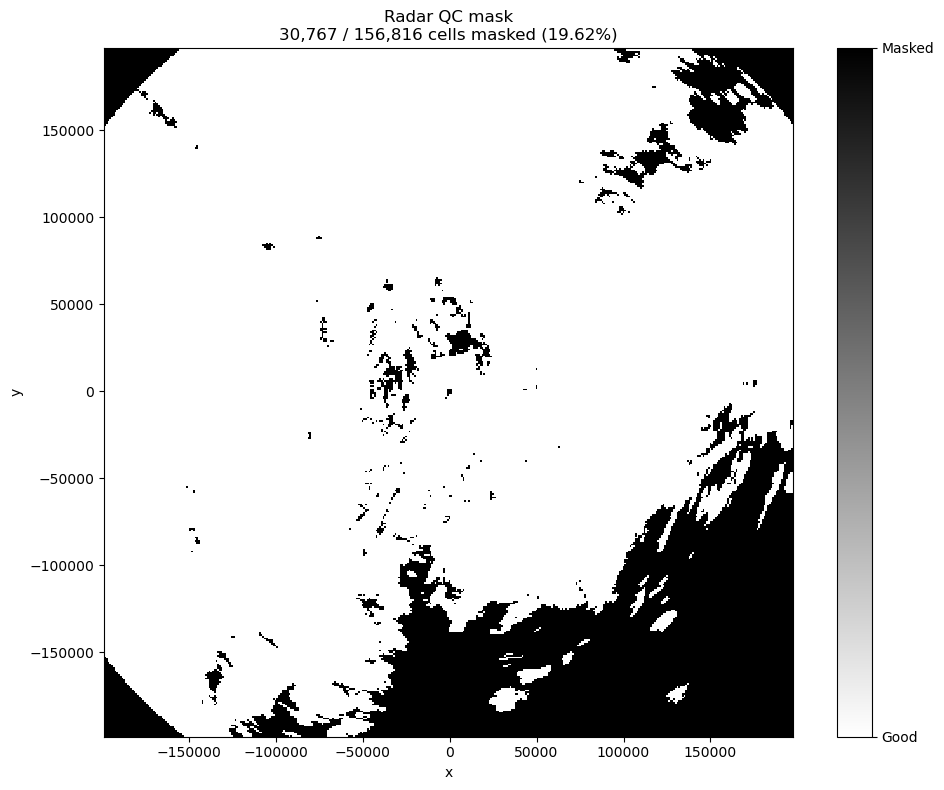

In [4]:
# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.pcolormesh(
    mask["x"],
    mask["y"],
    mask.astype(int),
    shading="auto",
    cmap="binary",
    vmin=0,
    vmax=1,
)

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=[0, 1],
)

cbar.ax.set_yticklabels([
    "Good",
    "Masked",
])

ax.set_title(
    f"Radar QC mask\n"
    f"{n_masked:,} / {n_total:,} cells masked "
    f"({n_masked / n_total:.2%})"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()